## Notebook for Figure 4, Figure 5, Supplementary Table 3. 



### load the score_matrics so that I can combine and do the PCA together.

In [1]:
import matplotlib

matplotlib.rcParams.update({
    "font.family":     "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    # your labels use $\rho$ and $^+$ — without this, math text renders in
    # Computer Modern (serif) while everything around it is Arial
    "mathtext.fontset": "custom",
    "mathtext.rm":      "Arial",
    "mathtext.it":      "Arial:italic",
    "mathtext.bf":      "Arial:bold",
    # keep text as text in vector output so it stays editable in Illustrator
    "svg.fonttype":     "none",
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
})

In [2]:
from pathlib import Path
import pandas as pd

input_dir1 = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_0913_combine_6_models/')
input_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/')

all_dfs = []

for file_path in input_dir1.glob("*predicts_sum_proportions_df.csv"):
    # Read the file
    df = pd.read_csv(file_path)

    # Extract the prefix from the file stem
    stem = file_path.stem  # e.g., study1_sample1_predicts_sum_proportions_df
    prefix = "_".join(stem.split("_")[:2])  # First two parts

    # Add 'study_sample' column
    df["study_sample"] = prefix + "_" + df["sample"].astype(str)

    # Optional: You can ensure 'Response_detail' exists by adding a placeholder if missing
    if 'Response_detail' not in df.columns:
        df['Response_detail'] = pd.NA

    all_dfs.append(df)

# Concatenate all DataFrames
score_matrix = pd.concat(all_dfs, ignore_index=True)


In [3]:
score_matrix.shape

(93, 12)

In [4]:

print(score_matrix.head)

<bound method NDFrame.head of     Unnamed: 0   score_0   score_1   score_2   score_3   score_4   score_5  \
0            0  0.863636  0.045455  0.000000  0.045455  0.022727  0.022727   
1            1  0.784694  0.075510  0.060204  0.026531  0.020408  0.016327   
2            2  0.384615  0.173077  0.076923  0.019231  0.076923  0.096154   
3            3  0.535491  0.096033  0.066806  0.074113  0.061587  0.068894   
4            4  0.817204  0.096774  0.035842  0.017921  0.017921  0.010753   
..         ...       ...       ...       ...       ...       ...       ...   
88          11  0.855856  0.063063  0.045045  0.018018  0.018018  0.000000   
89          12  0.429806  0.133909  0.105832  0.110151  0.069114  0.077754   
90          13  0.796053  0.085526  0.048246  0.043860  0.015351  0.010965   
91          14  0.493506  0.090909  0.077922  0.064935  0.064935  0.077922   
92          15  0.706897  0.120690  0.086207  0.017241  0.034483  0.017241   

     score_6          sample     

In [5]:
set(['_'.join(x.split('_')[:2]) for x in list(score_matrix['study_sample'].unique())])

{'Bassez_cohort1',
 'Bassez_cohort2',
 'Cappuyns_tumor',
 'chen_CRC',
 'chiffelle_15samples'}

In [6]:
score_matrix['Response_detail'].unique()

array([nan, 'SD', 'CR', 'PD', 'PR'], dtype=object)

In [7]:
from skbio.stats.distance import DistanceMatrix
from skbio.stats.distance import permanova
from scipy.spatial.distance import pdist, squareform

# Assume `score_matrix` is your patient-level dataframe
# with columns: ['score_0', ..., 'score_6', 'category']

# 1. Extract just the 7D vectors
X = score_matrix[[f'score_{i}' for i in range(7)]].values

# 2. Compute distance matrix (you can use 'euclidean', 'braycurtis', etc.)
dist = squareform(pdist(X, metric='euclidean'))  # or 'braycurtis', 'cityblock', etc.
dm = DistanceMatrix(dist, ids=score_matrix['sample'].tolist())

score_matrix.set_index('sample', inplace=True)
grouping = score_matrix['Response']  # This is now indexed by patient_id

# 3. Perform PERMANOVA
results = permanova(dm, grouping=grouping, permutations=999, seed=0)
print(results)

method name               PERMANOVA
test statistic name        pseudo-F
sample size                      93
number of groups                  2
test statistic            35.607063
p-value                       0.001
number of permutations          999
Name: PERMANOVA results, dtype: object


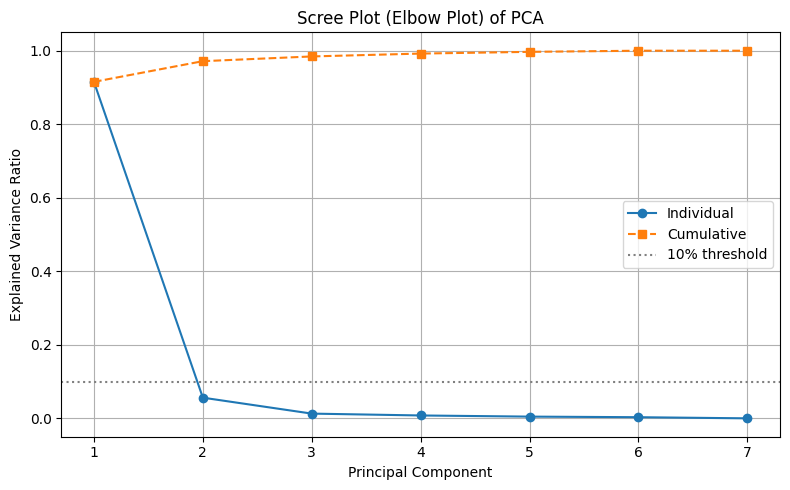

In [24]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

X = score_matrix[[f'score_{i}' for i in range(7)]].values

pca = PCA()
X_pca_full = pca.fit_transform(X)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Elbow plot (scree)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance)+1), explained_variance, marker='o', label='Individual')
plt.plot(range(1, len(explained_variance)+1), cumulative_variance, marker='s', linestyle='--', label='Cumulative')
plt.axhline(0.1, color='gray', linestyle=':', label='10% threshold')  # Optional visual aid
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot (Elbow Plot) of PCA')
plt.xticks(range(1, len(explained_variance)+1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
explained_variance[0]

0.9153001682961964

In [11]:
# ── Global typography / style ─────────────────────────────────────────────────
FS_TITLE  = 26
FS_LABEL  = 20
FS_TICK   = 19
FS_PVAL   = 18
FS_SPEAR  = 18
LW_BOX    = 1.2
DOT_SIZE  = 6
DOT_COLOR = '#C0392B'
DOT_ALPHA = 0.75
SPEAR_COLOR = '#1A5276'

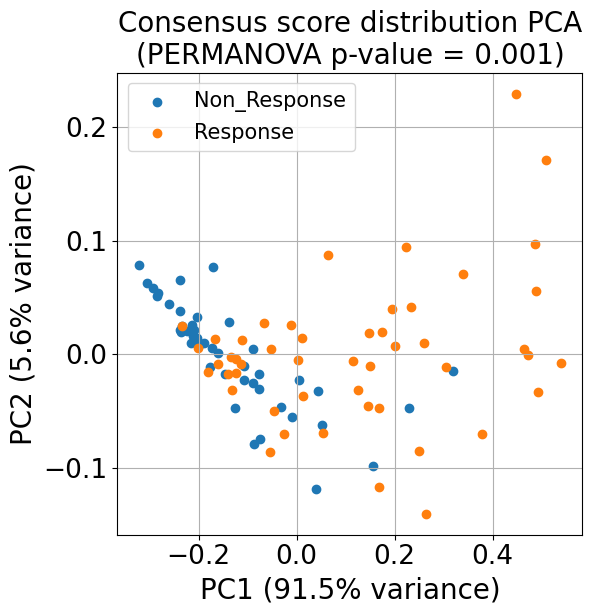

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X = score_matrix[[f'score_{i}' for i in range(7)]].values
y = score_matrix['Response'].values

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(6, 6))
for label in np.unique(y):
    idx = y == label
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=label)
plt.xlabel(f"PC1 ({explained_variance[0]* 100:.1f}% variance)", fontsize=FS_LABEL)
plt.ylabel(f"PC2 ({explained_variance[1]* 100:.1f}% variance)", fontsize=FS_LABEL)
plt.title(f"Consensus score distribution PCA\n(PERMANOVA p-value = {results['p-value']})", fontsize=FS_LABEL)
plt.tick_params(labelsize=FS_TICK)
plt.legend(fontsize=FS_TICK-4)
plt.grid(True)
# Save the plot
plt.savefig(f"{input_dir}/PatientScoreDistribution_PCA_editable..svg",  bbox_inches='tight')
# self-contained, for PowerPoint
with matplotlib.rc_context({"svg.fonttype": "path"}):
    plt.savefig(f"{input_dir}/PatientScoreDistribution_PCA.svg", bbox_inches="tight")

plt.show()


#### This detail-level plot is not proper since lots of samples do not have such annotation

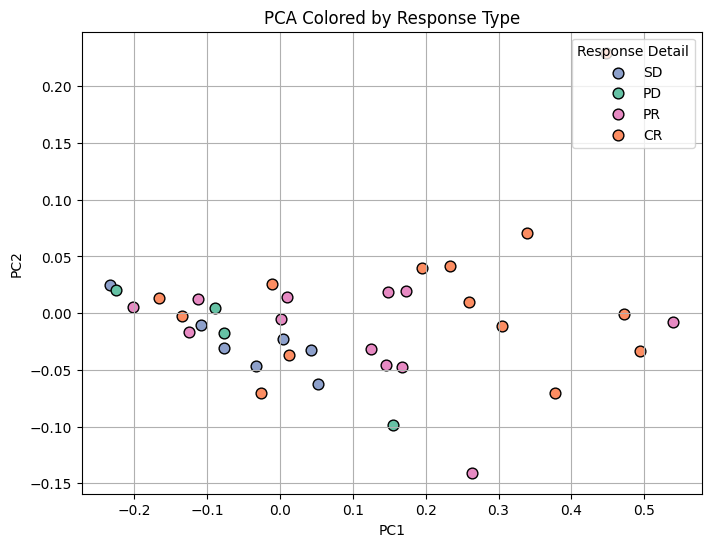

In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 1: Extract features and fine-level labels
X = score_matrix[[f'score_{i}' for i in range(7)]].values
y_fine = score_matrix['Response_detail'].values  # e.g., ['A-1', 'A-2', 'B-1', ...]

# Step 2: Run PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


set2_palette = sns.color_palette("Set2", n_colors=4)

# Create a custom palette for the categories
custom_palette = {
    'SD': set2_palette[2],  # Blue from Set2 
    'PD': set2_palette[0],  # Green from Set2
    'PR': set2_palette[3],   # Purple from Set2
    'CR':  set2_palette[1],  # Orange from Set2
}

"""
custom_palette = {
    'Non_Response': set2_palette[2],  # Blue from Set2 
#    'PD': set2_palette[0],  # Green from Set2
#    'PR': set2_palette[3],   # Purple from Set2
    'Response':  set2_palette[1],  # Orange from Set2
}
"""



# Step 3: Plot each subcategory with its own color and label
plt.figure(figsize=(8, 6))
for label in custom_palette.keys():
    idx = score_matrix['Response_detail'] == label
    plt.scatter(
        X_pca[idx, 0],
        X_pca[idx, 1],
        label=label,
        color=custom_palette[label],
        s=60,
        edgecolor='k'
    )

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Colored by Response Type')
plt.legend(title='Response Detail', bbox_to_anchor=(1.00, 1), loc='upper right', frameon=True)
plt.grid(True)
# Save the plot
#plt.savefig(f"{out_dir}/{str_title}_{cancer_type}_PatientScoreDistribution_PCA_detail.png", dpi=300, bbox_inches='tight')
plt.show()



In [8]:
score_matrix.columns

Index(['Unnamed: 0', 'score_0', 'score_1', 'score_2', 'score_3', 'score_4',
       'score_5', 'score_6', 'Response', 'study_sample', 'Response_detail'],
      dtype='object')

In [9]:
score_matrix.head(5)

,Unnamed: 0,score_0,score_1,score_2,score_3,score_4,score_5,score_6,Response,study_sample,Response_detail
sample,,,,,,,,,,,
BIOKEY_32_Pre,0,0.863636,0.045455,0.000000,0.045455,0.022727,0.022727,0.000000,Non_Response,Bassez_cohort2_BIOKEY_32_Pre,NaN
BIOKEY_33_Pre,1,0.784694,0.075510,0.060204,0.026531,0.020408,0.016327,0.016327,Response,Bassez_cohort2_BIOKEY_33_Pre,NaN
BIOKEY_34_Pre,2,0.384615,0.173077,0.076923,0.019231,0.076923,0.096154,0.173077,Non_Response,Bassez_cohort2_BIOKEY_34_Pre,NaN
BIOKEY_35_Pre,3,0.535491,0.096033,0.066806,0.074113,0.061587,0.068894,0.097077,Response,Bassez_cohort2_BIOKEY_35_Pre,NaN
BIOKEY_36_Pre,4,0.817204,0.096774,0.035842,0.017921,0.017921,0.010753,0.003584,Response,Bassez_cohort2_BIOKEY_36_Pre,NaN


In [10]:
# 1. Remove the first column
score_matrix = score_matrix.iloc[:, 1:]

# 2. Create a new column 'predict_rate' as the sum of score_4, score_5, score_6
score_matrix["predict_rate"] = score_matrix[["score_5", "score_6"]].sum(axis=1) # "score_3", "score_4", 

In [11]:
score_matrix.head(5)

,score_0,score_1,score_2,score_3,score_4,score_5,score_6,Response,study_sample,Response_detail,predict_rate
sample,,,,,,,,,,,
BIOKEY_32_Pre,0.863636,0.045455,0.000000,0.045455,0.022727,0.022727,0.000000,Non_Response,Bassez_cohort2_BIOKEY_32_Pre,NaN,0.022727
BIOKEY_33_Pre,0.784694,0.075510,0.060204,0.026531,0.020408,0.016327,0.016327,Response,Bassez_cohort2_BIOKEY_33_Pre,NaN,0.032653
BIOKEY_34_Pre,0.384615,0.173077,0.076923,0.019231,0.076923,0.096154,0.173077,Non_Response,Bassez_cohort2_BIOKEY_34_Pre,NaN,0.269231
BIOKEY_35_Pre,0.535491,0.096033,0.066806,0.074113,0.061587,0.068894,0.097077,Response,Bassez_cohort2_BIOKEY_35_Pre,NaN,0.165971
BIOKEY_36_Pre,0.817204,0.096774,0.035842,0.017921,0.017921,0.010753,0.003584,Response,Bassez_cohort2_BIOKEY_36_Pre,NaN,0.014337


In [12]:
score_matrix.tail(5)

,score_0,score_1,score_2,score_3,score_4,score_5,score_6,Response,study_sample,Response_detail,predict_rate
sample,,,,,,,,,,,
Cappuyns_pat33,0.855856,0.063063,0.045045,0.018018,0.018018,0.000000,0.000000,Non_Response,Cappuyns_tumor_Cappuyns_pat33,NaN,0.000000
Cappuyns_pat34,0.429806,0.133909,0.105832,0.110151,0.069114,0.077754,0.073434,Response,Cappuyns_tumor_Cappuyns_pat34,NaN,0.151188
Cappuyns_pat35,0.796053,0.085526,0.048246,0.043860,0.015351,0.010965,0.000000,Response,Cappuyns_tumor_Cappuyns_pat35,NaN,0.010965
Cappuyns_pat36,0.493506,0.090909,0.077922,0.064935,0.064935,0.077922,0.129870,Response,Cappuyns_tumor_Cappuyns_pat36,NaN,0.207792
Cappuyns_pat37,0.706897,0.120690,0.086207,0.017241,0.034483,0.017241,0.017241,Response,Cappuyns_tumor_Cappuyns_pat37,NaN,0.034483


In [19]:
predict_rate = score_matrix.groupby(['Response', 'study_sample'])['predict_rate'].mean().reset_index()

# Rename the column for clarity

predict_rate.dropna(subset=['predict_rate'], inplace=True)
print(predict_rate)

        Response                               study_sample  predict_rate
0   Non_Response               Bassez_cohort1_BIOKEY_14_Pre      0.013761
1   Non_Response               Bassez_cohort1_BIOKEY_17_Pre      0.000000
2   Non_Response               Bassez_cohort1_BIOKEY_19_Pre      0.001828
3   Non_Response               Bassez_cohort1_BIOKEY_20_Pre      0.088889
4   Non_Response               Bassez_cohort1_BIOKEY_21_Pre      0.000000
..           ...                                        ...           ...
88      Response  chiffelle_15samples_chiffelle_Patient2_T0      0.082107
89      Response  chiffelle_15samples_chiffelle_Patient3_T0      0.311072
90      Response  chiffelle_15samples_chiffelle_Patient7_T0      0.146520
91      Response  chiffelle_15samples_chiffelle_Patient8_T0      0.383489
92      Response  chiffelle_15samples_chiffelle_Patient9_T0      0.140442

[93 rows x 3 columns]


In [20]:
predict_rate.head(5)

,Response,study_sample,predict_rate
0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.013761
1,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.000000
2,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.001828
3,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889
4,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.000000


In [21]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from scipy.stats import mannwhitneyu
# Spearman’s rho
import scipy.stats as stats




def _draw_brackets(ax, sig_pairs, y_data_max, y_range,
                   gap_frac=0.06, step_frac=0.13, bar_frac=0.025):
    """Draw stacked significance brackets in data coordinates."""
    for level, (xa, xb, p_val) in enumerate(sig_pairs):
        y_bot = y_data_max + y_range * (gap_frac + level * step_frac)
        y_top = y_bot + y_range * bar_frac
        ax.plot([xa, xa, xb, xb], [y_bot, y_top, y_top, y_bot],
                lw=1.0, color='black', clip_on=False)
        ax.text((xa + xb) / 2, y_top + y_range * 0.01, _pval_str(p_val),
                ha='center', va='bottom', fontsize=FS_PVAL, color='red',
                fontweight='bold', clip_on=False)

def _pval_str(p):
    """Format a p-value for annotation."""
    if p < 1e-4:
        return f"{p:.1e}"
    elif p < 0.001:
        return "P < 0.001"
    else:
        return f"{p:.3f}"


def _bracket_headroom(n_levels, gap_frac=0.06, step_frac=0.13,
                      bar_frac=0.025, text_frac=0.06):
    """Fractional y-range needed above the data for n stacked brackets."""
    return gap_frac + max(n_levels - 1, 0) * step_frac + bar_frac + text_frac


set2_palette = sns.color_palette("Set2", n_colors=4)
custom_palette = {
    'Non_Response': set2_palette[2],
    'Response':     set2_palette[1],
}


def plot_fraction_by_response(
        df, y_col, y_label, out_stem,
        group_col='Response',
        group_order=('Non_Response', 'Response'),
        group_labels=('Non_Response', 'Response'),
        palette=None,
        title=None,
        show_spearman=True,
        figsize=(6, 6)):
    """Boxplot + stripplot of a per-sample fraction across response groups,
    annotated with a Mann-Whitney bracket and optional Spearman rho."""

    group_order = list(group_order)
    d = df[[group_col, y_col]].dropna().copy()
    d[group_col] = pd.Categorical(d[group_col], categories=group_order, ordered=True)

    a = d.loc[d[group_col] == group_order[0], y_col]
    b = d.loc[d[group_col] == group_order[1], y_col]
    if a.empty or b.empty:
        raise ValueError(f"{y_col}: one or both groups are empty "
                         f"(n={len(a)}, {len(b)})")

    stat, p_value = mannwhitneyu(a, b, alternative='two-sided')

    # Rank-biserial correlation: the natural effect size for U
    rbc = 1 - (2 * stat) / (len(a) * len(b))

    print(f"{y_col}: n={len(a)} vs {len(b)} | U={stat:.1f} | "
          f"P={p_value:.3e} | rank-biserial r={rbc:.3f}")

    fig, ax = plt.subplots(figsize=figsize)

    sns.boxplot(data=d, x=group_col, y=y_col, order=group_order,
                hue=group_col, palette=palette, linewidth=LW_BOX,
                showfliers=False, legend=False, ax=ax)
    sns.stripplot(data=d, x=group_col, y=y_col, order=group_order,
                  color=DOT_COLOR, alpha=DOT_ALPHA, size=DOT_SIZE,
                  jitter=0.18, ax=ax)

    y_min, y_max = d[y_col].min(), d[y_col].max()
    y_range = y_max - y_min

    sig_pairs = [(0, 1, p_value)]
    _draw_brackets(ax, sig_pairs, y_max, y_range)
    ax.set_ylim(y_min - y_range * 0.05,
                y_max + y_range * _bracket_headroom(len(sig_pairs)))

    if show_spearman:
        code = d[group_col].cat.codes          # 0 / 1, follows group_order
        rho, rho_p = stats.spearmanr(code, d[y_col])
        ax.text(0.03, 0.90,
                f"Spearman's $\\rho$: {rho:.3f}\np-value: {rho_p:.2e}",
                transform=ax.transAxes, ha='left', va='top',
                fontsize=FS_SPEAR, color=SPEAR_COLOR)

    ax.set_ylabel(y_label, fontsize=FS_LABEL)
    ax.set_xlabel("Response", fontsize=FS_LABEL)
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(group_labels, fontsize=FS_TICK)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    if title:
        ax.set_title(title, fontsize=FS_TITLE)
    sns.despine(ax=ax)

    for ext, kw in [("pdf", {}), ("png", {"dpi": 600})]:
        fig.savefig(f"{out_stem}.{ext}", bbox_inches="tight", **kw)

    # editable, for Illustrator
    with matplotlib.rc_context({"svg.fonttype": "none"}):
        fig.savefig(f"{out_stem}_editable.svg", bbox_inches="tight")
    
    # self-contained, for PowerPoint
    with matplotlib.rc_context({"svg.fonttype": "path"}):
        fig.savefig(f"{out_stem}.svg", bbox_inches="tight")
    plt.show()
    plt.close()

    return {'U': stat, 'p': p_value, 'rank_biserial': rbc, 'n': (len(a), len(b))}

predict_rate: n=44 vs 49 | U=341.0 | P=1.259e-08 | rank-biserial r=0.684


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


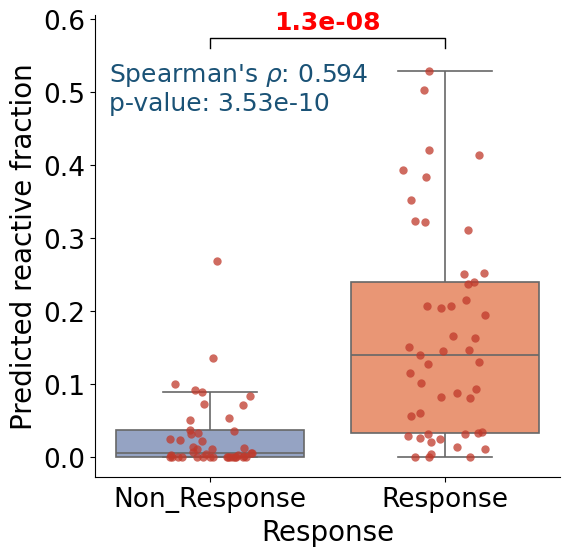

In [22]:
res_rate = plot_fraction_by_response(
    predict_rate,
    y_col='predict_rate',
    y_label="Predicted reactive fraction",
    title=None,
    out_stem=f"{input_dir}/predictRate_byResponse_box_plot_include0",
    palette=custom_palette,
)

In [23]:
predict_rate['Response'].value_counts()

Response        49
Non_Response    44
Name: Response, dtype: int64

In [24]:
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

df = predict_rate
df['Response_binary'] = df['Response'].map({
    'Response': 1,
    'Non_Response': 0
})

# 2. Get true labels and prediction scores
y_true = df['Response_binary']
y_score = df['predict_rate']

# 3. Calculate AUC
auc = roc_auc_score(y_true, y_score)
print("AUC:", auc)

AUC: 0.8418367346938775


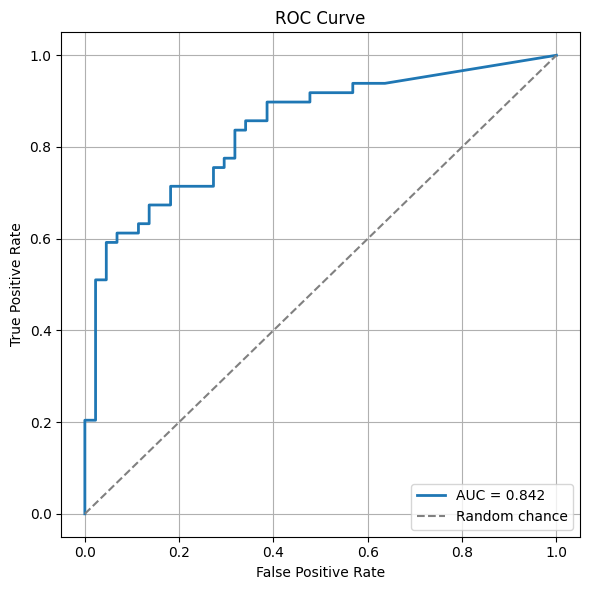

In [25]:
# Compute ROC curve points
fpr, tpr, thresholds = roc_curve(y_true, y_score)

# Plot ROC curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
dfs = {
    "Predict Rate": predict_rate,
    #"Dataset 2": df2,
    #"Dataset 3": df3
}

In [27]:
import os 
#os.listdir(input_dir)

In [28]:
for file_path in input_dir.glob("*predictRate_box_plot_include0.csv"):
    # Read the file
    df = pd.read_csv(file_path)
    print(df.columns)

Index(['Unnamed: 0', 'Response', 'sample', 'timepoint', 'predict_rate',
       '_code'],
      dtype='object')
Index(['Unnamed: 0', 'Response_detail', 'sample', 'predict_rate',
       'Response_detailCode'],
      dtype='object')
Index(['Unnamed: 0', 'Response', 'sample', 'predict_rate', '_code'], dtype='object')
Index(['Unnamed: 0', 'Response', 'sample', 'predict_rate', '_code'], dtype='object')
Index(['Unnamed: 0', 'Response_detail', 'sample', 'predict_rate',
       'Response_detailCode'],
      dtype='object')


### CXCL13

In [29]:
from pathlib import Path
import pandas as pd



all_dfs = []

for file_path in input_dir1.glob("*proportion_CXCL13_positive.csv"):
    # Read the file
    df = pd.read_csv(file_path)
    if "proportion_cxcl13_positive" in df.columns:
        df = df.rename(columns={"proportion_cxcl13_positive": "proportion_CXCL13_positive"})

    # Extract the prefix from the file stem
    stem = file_path.stem  # e.g., study1_sample1_predicts_sum_proportions_df
    prefix = "_".join(stem.split("_")[:2])  # First two parts


    all_dfs.append(df)

# Concatenate all DataFrames
cxcl13_matrix = pd.concat(all_dfs, ignore_index=True)


In [30]:
cxcl13_matrix

,Unnamed: 0,sample,proportion_CXCL13_positive,Response,study_sample,Response_detail
0,0,BIOKEY_2_Pre,0.003279,Non_Response,Bassez_cohort1_BIOKEY_2_Pre,NaN
1,305,BIOKEY_3_Pre,0.043956,Non_Response,Bassez_cohort1_BIOKEY_3_Pre,NaN
2,396,BIOKEY_4_Pre,0.074837,Non_Response,Bassez_cohort1_BIOKEY_4_Pre,NaN
3,1318,BIOKEY_5_Pre,0.205594,Response,Bassez_cohort1_BIOKEY_5_Pre,NaN
4,2033,BIOKEY_6_Pre,0.000000,Non_Response,Bassez_cohort1_BIOKEY_6_Pre,NaN
...,...,...,...,...,...,...
88,13675,chiffelle_Patient10_T02,0.182482,Non_Response,chiffelle_15samples_chiffelle_Patient10_T02,NaN
89,14634,chiffelle_Patient11_T0,0.023941,Non_Response,chiffelle_15samples_chiffelle_Patient11_T0,NaN
90,15177,chiffelle_Patient12_T0,0.014354,Non_Response,chiffelle_15samples_chiffelle_Patient12_T0,NaN
91,15386,chiffelle_Patient13_T01,0.364407,Response,chiffelle_15samples_chiffelle_Patient13_T01,NaN


In [31]:
set(cxcl13_matrix['study_sample'].to_list()) - set(score_matrix['study_sample'].to_list())

set()

In [32]:
# 1. Remove the first column
cxcl13_matrix = cxcl13_matrix.iloc[:, 1:]

In [33]:
cxcl13_matrix

,sample,proportion_CXCL13_positive,Response,study_sample,Response_detail
0,BIOKEY_2_Pre,0.003279,Non_Response,Bassez_cohort1_BIOKEY_2_Pre,NaN
1,BIOKEY_3_Pre,0.043956,Non_Response,Bassez_cohort1_BIOKEY_3_Pre,NaN
2,BIOKEY_4_Pre,0.074837,Non_Response,Bassez_cohort1_BIOKEY_4_Pre,NaN
3,BIOKEY_5_Pre,0.205594,Response,Bassez_cohort1_BIOKEY_5_Pre,NaN
4,BIOKEY_6_Pre,0.000000,Non_Response,Bassez_cohort1_BIOKEY_6_Pre,NaN
...,...,...,...,...,...
88,chiffelle_Patient10_T02,0.182482,Non_Response,chiffelle_15samples_chiffelle_Patient10_T02,NaN
89,chiffelle_Patient11_T0,0.023941,Non_Response,chiffelle_15samples_chiffelle_Patient11_T0,NaN
90,chiffelle_Patient12_T0,0.014354,Non_Response,chiffelle_15samples_chiffelle_Patient12_T0,NaN
91,chiffelle_Patient13_T01,0.364407,Response,chiffelle_15samples_chiffelle_Patient13_T01,NaN


In [34]:
predict_rate = cxcl13_matrix.groupby(['Response', 'study_sample'])['proportion_CXCL13_positive'].mean().reset_index()

# Rename the column for clarity

predict_rate.dropna(subset=['proportion_CXCL13_positive'], inplace=True)
print(predict_rate)

        Response                               study_sample  \
0   Non_Response               Bassez_cohort1_BIOKEY_14_Pre   
1   Non_Response               Bassez_cohort1_BIOKEY_17_Pre   
2   Non_Response               Bassez_cohort1_BIOKEY_19_Pre   
3   Non_Response               Bassez_cohort1_BIOKEY_20_Pre   
4   Non_Response               Bassez_cohort1_BIOKEY_21_Pre   
..           ...                                        ...   
88      Response  chiffelle_15samples_chiffelle_Patient2_T0   
89      Response  chiffelle_15samples_chiffelle_Patient3_T0   
90      Response  chiffelle_15samples_chiffelle_Patient7_T0   
91      Response  chiffelle_15samples_chiffelle_Patient8_T0   
92      Response  chiffelle_15samples_chiffelle_Patient9_T0   

    proportion_CXCL13_positive  
0                     0.006881  
1                     0.020833  
2                     0.000000  
3                     0.088889  
4                     0.000000  
..                         ...  
88          

proportion_CXCL13_positive: n=44 vs 49 | U=464.0 | P=2.011e-06 | rank-biserial r=0.570


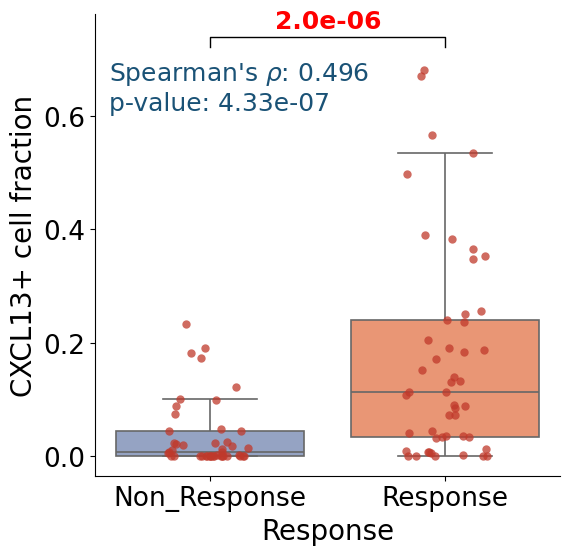

In [35]:
gene_name = 'CXCL13'

res_gene = plot_fraction_by_response(
    predict_rate,
    y_col=f'proportion_{gene_name}_positive',
    y_label=f"{gene_name}+ cell fraction",
    title=None,
    out_stem=f"{input_dir}/{gene_name}_ExpressionRate_box_plot",
    palette=custom_palette,
)

In [36]:
predict_rate

,Response,study_sample,proportion_CXCL13_positive
0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.006881
1,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.020833
2,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.000000
3,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889
4,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.000000
...,...,...,...
88,Response,chiffelle_15samples_chiffelle_Patient2_T0,0.113865
89,Response,chiffelle_15samples_chiffelle_Patient3_T0,0.680617
90,Response,chiffelle_15samples_chiffelle_Patient7_T0,0.152015
91,Response,chiffelle_15samples_chiffelle_Patient8_T0,0.670375


In [37]:
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

df = predict_rate
df['Response_binary'] = df['Response'].map({
    'Response': 1,
    'Non_Response': 0
})

# 2. Get true labels and prediction scores
y_true = df['Response_binary']
y_score = df[f'proportion_{gene_name}_positive']

# 3. Calculate AUC
auc = roc_auc_score(y_true, y_score)
print("AUC:", auc)

AUC: 0.7847866419294991


In [38]:
dfs[f"{gene_name} Expression Rate"] =  df


In [39]:
dfs[f"Predict Rate"]

,Response,study_sample,predict_rate,Response_binary
0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.013761,0
1,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.000000,0
2,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.001828,0
3,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889,0
4,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.000000,0
...,...,...,...,...
88,Response,chiffelle_15samples_chiffelle_Patient2_T0,0.082107,1
89,Response,chiffelle_15samples_chiffelle_Patient3_T0,0.311072,1
90,Response,chiffelle_15samples_chiffelle_Patient7_T0,0.146520,1
91,Response,chiffelle_15samples_chiffelle_Patient8_T0,0.383489,1


### predicts_rank_sum_normalized 

In [40]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [41]:
from scipy.stats import mannwhitneyu
# Spearman’s rho
import scipy.stats as stats

In [42]:
from pathlib import Path
import pandas as pd



all_dfs = []

for file_path in input_dir.glob("*predicts_rank_sum_normalized*.csv"):
    # Read the file
    df = pd.read_csv(file_path)

    # Extract the prefix from the file stem
    stem = file_path.stem  # e.g., study1_sample1_predicts_sum_proportions_df
    prefix = "_".join(stem.split("_")[:2])  # First two parts


    all_dfs.append(df)

# Concatenate all DataFrames
cxcl13_matrix = pd.concat(all_dfs, ignore_index=True)
sample_response_dict = score_matrix['Response'].to_dict()
#print(sample_response_dict)
# Step 2: Map it onto predictRateTem_matrix based on its 'sample' column
cxcl13_matrix['Response'] = cxcl13_matrix['sample'].map(sample_response_dict)

In [43]:
cxcl13_matrix

,Unnamed: 0,sample,timepoint,Response,predicts_rank_sum_normalized,_code,study_sample,Timepoint,Response_detail,Response_detailCode,Week,Treatment,Tissue
0,0,BIOKEY_2_Pre,Pre,Non_Response,0.332292,1.0,Bassez_cohort1_BIOKEY_2_Pre,NaN,NaN,NaN,NaN,NaN,NaN
1,1,BIOKEY_3_Pre,Pre,Non_Response,0.314755,1.0,Bassez_cohort1_BIOKEY_3_Pre,NaN,NaN,NaN,NaN,NaN,NaN
2,2,BIOKEY_4_Pre,Pre,Non_Response,0.356036,1.0,Bassez_cohort1_BIOKEY_4_Pre,NaN,NaN,NaN,NaN,NaN,NaN
3,3,BIOKEY_5_Pre,Pre,Response,0.565385,2.0,Bassez_cohort1_BIOKEY_5_Pre,NaN,NaN,NaN,NaN,NaN,NaN
4,4,BIOKEY_6_Pre,Pre,Non_Response,0.397297,1.0,Bassez_cohort1_BIOKEY_6_Pre,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,6,BIOKEY_38_Pre,Pre,Non_Response,0.348399,NaN,Bassez_cohort2_BIOKEY_38_Pre,NaN,NaN,1.0,NaN,NaN,NaN
89,7,BIOKEY_39_Pre,Pre,Non_Response,0.381876,NaN,Bassez_cohort2_BIOKEY_39_Pre,NaN,NaN,1.0,NaN,NaN,NaN
90,8,BIOKEY_40_Pre,Pre,Non_Response,0.406829,NaN,Bassez_cohort2_BIOKEY_40_Pre,NaN,NaN,1.0,NaN,NaN,NaN
91,9,BIOKEY_41_Pre,Pre,Non_Response,0.437209,NaN,Bassez_cohort2_BIOKEY_41_Pre,NaN,NaN,1.0,NaN,NaN,NaN


In [44]:
set(cxcl13_matrix['study_sample'].to_list()) - set(score_matrix['study_sample'].to_list())

set()

In [45]:
# 1. Remove the first column
cxcl13_matrix = cxcl13_matrix.iloc[:, 1:]

In [46]:
column_name = 'predicts_rank_sum_normalized'
predict_rate = cxcl13_matrix.groupby(['Response', 'sample'])[column_name].mean().reset_index()

# Rename the column for clarity

predict_rate.dropna(subset=['predicts_rank_sum_normalized'], inplace=True)
print(predict_rate.shape)

(93, 3)


predicts_rank_sum_normalized: n=44 vs 49 | U=444.0 | P=1.090e-06 | rank-biserial r=0.588


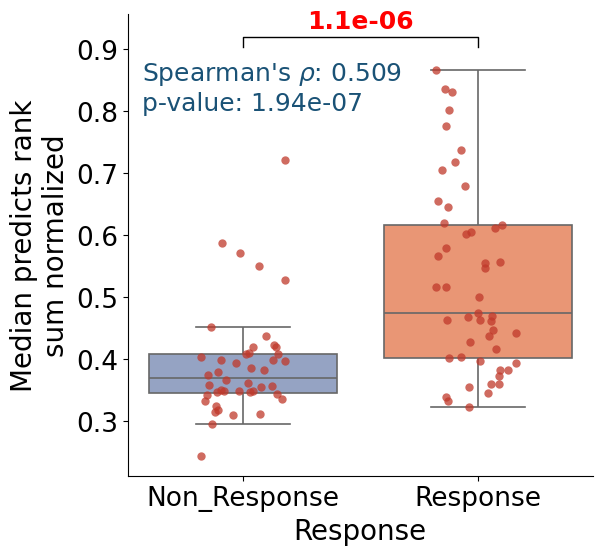

In [47]:
res_rate = plot_fraction_by_response(
    predict_rate,
    y_col='predicts_rank_sum_normalized',
    y_label="Median predicts rank\nsum normalized",
    title=None,
    out_stem=f"{input_dir}/Normalized_Predicts_Rank_Sum_box_plot",
    palette=custom_palette,
)

In [48]:
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

df = predict_rate
df['Response_binary'] = df['Response'].map({
    'Response': 1,
    'Non_Response': 0
})

# 2. Get true labels and prediction scores
y_true = df['Response_binary']
y_score = df[column_name]

# 3. Calculate AUC
auc = roc_auc_score(y_true, y_score)
print("AUC:", auc)

AUC: 0.7940630797773655


In [49]:
dfs[f"normalized predicts_rank_sum_"] =  df

In [50]:
list(dfs.keys())

['Predict Rate', 'CXCL13 Expression Rate', 'normalized predicts_rank_sum_']

In [51]:
dfs['normalized predicts_rank_sum_'].columns

Index(['Response', 'sample', 'predicts_rank_sum_normalized',
       'Response_binary'],
      dtype='object')

In [52]:
from pathlib import Path
import pandas as pd
gene_name = 'GZMB'


all_dfs = []

for file_path in input_dir1.glob(f"*proportion_{gene_name}_positive.csv"):
    # Read the file
    df = pd.read_csv(file_path)


    # Extract the prefix from the file stem
    stem = file_path.stem  # e.g., study1_sample1_predicts_sum_proportions_df
    prefix = "_".join(stem.split("_")[:2])  # First two parts


    all_dfs.append(df)

# Concatenate all DataFrames
cxcl13_matrix = pd.concat(all_dfs, ignore_index=True)


In [53]:
cxcl13_matrix.head()

,Unnamed: 0,sample,proportion_GZMB_positive,Response,study_sample,Response_detail
0,0,BIOKEY_32_Pre,0.295455,Non_Response,Bassez_cohort2_BIOKEY_32_Pre,NaN
1,44,BIOKEY_33_Pre,0.397959,Response,Bassez_cohort2_BIOKEY_33_Pre,NaN
2,1024,BIOKEY_34_Pre,0.730769,Non_Response,Bassez_cohort2_BIOKEY_34_Pre,NaN
3,1076,BIOKEY_35_Pre,0.454071,Response,Bassez_cohort2_BIOKEY_35_Pre,NaN
4,2034,BIOKEY_36_Pre,0.483871,Response,Bassez_cohort2_BIOKEY_36_Pre,NaN


In [54]:
set(cxcl13_matrix['study_sample'].to_list()) - set(score_matrix['study_sample'].to_list())

set()

In [55]:
# 1. Remove the first column
cxcl13_matrix = cxcl13_matrix.iloc[:, 1:]

In [56]:
cxcl13_matrix

,sample,proportion_GZMB_positive,Response,study_sample,Response_detail
0,BIOKEY_32_Pre,0.295455,Non_Response,Bassez_cohort2_BIOKEY_32_Pre,NaN
1,BIOKEY_33_Pre,0.397959,Response,Bassez_cohort2_BIOKEY_33_Pre,NaN
2,BIOKEY_34_Pre,0.730769,Non_Response,Bassez_cohort2_BIOKEY_34_Pre,NaN
3,BIOKEY_35_Pre,0.454071,Response,Bassez_cohort2_BIOKEY_35_Pre,NaN
4,BIOKEY_36_Pre,0.483871,Response,Bassez_cohort2_BIOKEY_36_Pre,NaN
...,...,...,...,...,...
88,CRC22-T-I,0.333333,Response,chen_CRC_CRC22-T-I,CR
89,CRC23-T-I,0.599265,Response,chen_CRC_CRC23-T-I,CR
90,CRC24-T-I,0.414634,Response,chen_CRC_CRC24-T-I,PR
91,CRC25-T-I,0.158103,Non_Response,chen_CRC_CRC25-T-I,SD


In [57]:
predict_rate = cxcl13_matrix.groupby(['Response', 'study_sample'])[f'proportion_{gene_name}_positive'].mean().reset_index()

# Rename the column for clarity

predict_rate.dropna(subset=[f'proportion_{gene_name}_positive'], inplace=True)
print(predict_rate)

        Response                               study_sample  \
0   Non_Response               Bassez_cohort1_BIOKEY_14_Pre   
1   Non_Response               Bassez_cohort1_BIOKEY_17_Pre   
2   Non_Response               Bassez_cohort1_BIOKEY_19_Pre   
3   Non_Response               Bassez_cohort1_BIOKEY_20_Pre   
4   Non_Response               Bassez_cohort1_BIOKEY_21_Pre   
..           ...                                        ...   
88      Response  chiffelle_15samples_chiffelle_Patient2_T0   
89      Response  chiffelle_15samples_chiffelle_Patient3_T0   
90      Response  chiffelle_15samples_chiffelle_Patient7_T0   
91      Response  chiffelle_15samples_chiffelle_Patient8_T0   
92      Response  chiffelle_15samples_chiffelle_Patient9_T0   

    proportion_GZMB_positive  
0                   0.149083  
1                   0.187500  
2                   0.115174  
3                   0.088889  
4                   0.153846  
..                       ...  
88                  0.4461

In [58]:
predict_rate

,Response,study_sample,proportion_GZMB_positive
0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.149083
1,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.187500
2,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.115174
3,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889
4,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.153846
...,...,...,...
88,Response,chiffelle_15samples_chiffelle_Patient2_T0,0.446166
89,Response,chiffelle_15samples_chiffelle_Patient3_T0,0.390324
90,Response,chiffelle_15samples_chiffelle_Patient7_T0,0.285714
91,Response,chiffelle_15samples_chiffelle_Patient8_T0,0.673302


proportion_GZMB_positive: n=44 vs 49 | U=413.0 | P=3.166e-07 | rank-biserial r=0.617


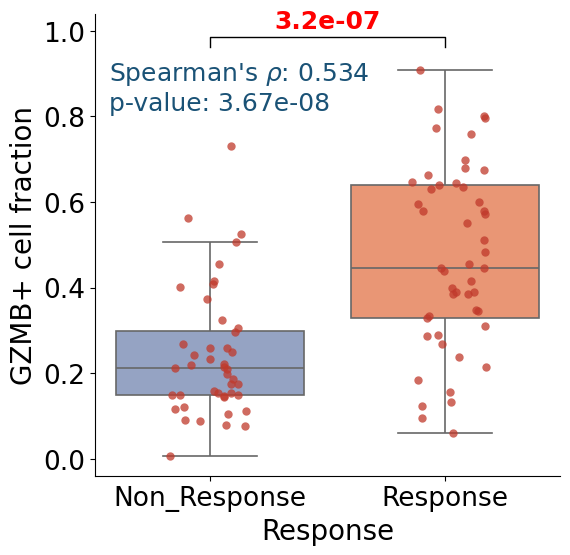

In [59]:
gene_name = 'GZMB'

res_gene = plot_fraction_by_response(
    predict_rate,
    y_col=f'proportion_{gene_name}_positive',
    y_label=f"{gene_name}+ cell fraction",
    title=None,
    out_stem=f"{input_dir}/{gene_name}_ExpressionRate_box_plot",
    palette=custom_palette,
)

In [60]:
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

df = predict_rate
df['Response_binary'] = df['Response'].map({
    'Response': 1,
    'Non_Response': 0
})

# 2. Get true labels and prediction scores
y_true = df['Response_binary']
y_score = df[f'proportion_{gene_name}_positive']

# 3. Calculate AUC
auc = roc_auc_score(y_true, y_score)
print("AUC:", auc) 

dfs["GZMB Expression Rate"] =  df

AUC: 0.8084415584415585


In [61]:
input_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform')

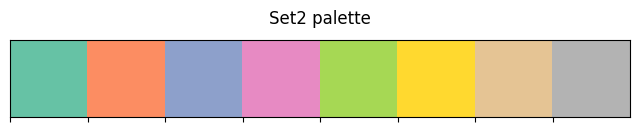

In [62]:
palette = sns.color_palette("Set2")
sns.palplot(palette)
plt.title("Set2 palette", pad=12)
plt.show()

In [63]:
list(dfs.keys())

['Predict Rate',
 'CXCL13 Expression Rate',
 'normalized predicts_rank_sum_',
 'GZMB Expression Rate']

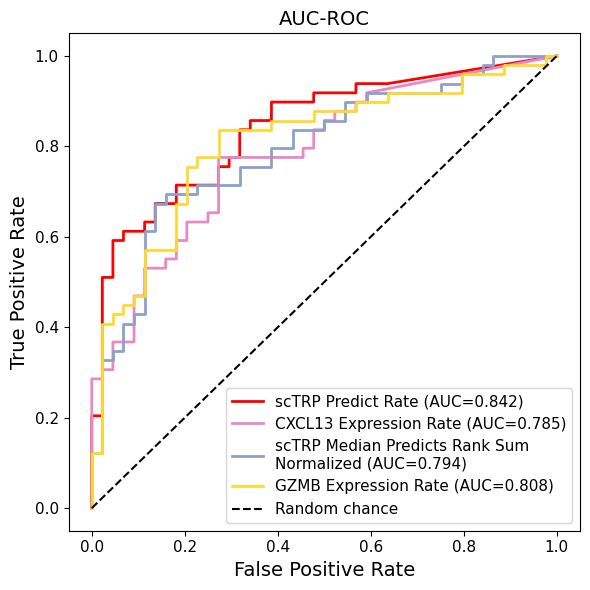

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve


""""
custom_palette = {
    'SD': set2_palette[2],  # Blue from Set2 
    'PD': set2_palette[0],  # Green from Set2
    'PR': set2_palette[3],   # Purple from Set2
    'CR':  set2_palette[1],  # Orange from Set2
}
"""

column_name_list = ['predict_rate', 'proportion_CXCL13_positive', 'predicts_rank_sum_normalized', 'proportion_GZMB_positive']
labels = ['scTRP Predict Rate', f'CXCL13 Expression Rate', 'scTRP Median Predicts Rank Sum\nNormalized', 'GZMB Expression Rate']
dfs_list = [dfs[x] for x in list(dfs.keys())]

set2_palette_list = list(sns.color_palette("Set2", n_colors=7))
colors = [(1, 0, 0)] + [set2_palette_list[3]] + [set2_palette_list[2]] + [set2_palette_list[5]]

# Get Set2 palette (as many colors as needed)
#set2_palette = sns.color_palette("Set2", n_colors=len(dfs))

plt.figure(figsize=(6, 6))

for (df, score_col, name, color) in zip(dfs_list, column_name_list, labels, colors):
    df = df.copy()
    df['Response_binary'] = df['Response'].map({
        'Response': 1,
        'Non_Response': 0
    })

    y_true = df['Response_binary']
    y_score = df[score_col]

    # Compute ROC + AUC
    auc = roc_auc_score(y_true, y_score)
    fpr, tpr, _ = roc_curve(y_true, y_score)

    # Plot ROC with fixed color
    plt.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC={auc:.3f})")

# Add baseline
plt.plot([0, 1], [0, 1], linestyle="--", color="black", label="Random chance")

# Labels
plt.xlabel("False Positive Rate", fontsize=14)
plt.ylabel("True Positive Rate", fontsize=14)
plt.title("AUC-ROC", fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.tick_params(axis='both', labelsize=11)
#plt.grid(True)
plt.tight_layout()
plt.savefig(f"{input_dir}/ROC_Curves_of_all_the_patients_4lines.svg", dpi=300, bbox_inches='tight')
plt.show()

In [65]:
f"{input_dir}/ROC_Curves_of_all_the_patients.png"

'/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/ROC_Curves_of_all_the_patients.png'

In [66]:
input_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform')

In [67]:
for key, df in dfs.items():
    if 'sample' in df.columns:
        continue
    if 'study_sample' not in df.columns:
        print(f"{key:25s}  SKIP: neither 'sample' nor 'study_sample'")
        continue

    parts = df['study_sample'].str.split('_', n=2)
    bad = parts.map(len) < 3
    if bad.any():
        raise ValueError(
            f"{key}: {bad.sum()} study_sample values have fewer than two "
            f"underscores: {df.loc[bad, 'study_sample'].unique()[:5]}"
        )

    df = df.copy()                      # don't mutate whatever else points here
    df['sample'] = parts.str[2]
    dfs[key] = df

    dup = df.loc[df['sample'].duplicated(keep=False), 'sample']
    print(f"{key:25s}  derived 'sample' from 'study_sample'  "
          f"n_unique = {df['sample'].nunique()}"
          + (f"  DUPLICATES: {sorted(set(dup))}" if len(dup) else ""))

Predict Rate               derived 'sample' from 'study_sample'  n_unique = 93
CXCL13 Expression Rate     derived 'sample' from 'study_sample'  n_unique = 93
GZMB Expression Rate       derived 'sample' from 'study_sample'  n_unique = 93


In [68]:
sets = {k: set(d['sample']) for k, d in dfs.items() if 'sample' in d.columns}
common = set.intersection(*sets.values())

for k, s in sets.items():
    extra = s - common
    print(f"{k:25s}  n = {len(s):3d}  not shared: {len(extra)}"
          + (f"  {sorted(extra)}" if extra else ""))

print(f"\nshared across all {len(sets)}: {len(common)}")

Predict Rate               n =  93  not shared: 0
CXCL13 Expression Rate     n =  93  not shared: 0
normalized predicts_rank_sum_  n =  93  not shared: 0
GZMB Expression Rate       n =  93  not shared: 0

shared across all 4: 93


In [69]:
dfs.keys()

dict_keys(['Predict Rate', 'CXCL13 Expression Rate', 'normalized predicts_rank_sum_', 'GZMB Expression Rate'])

In [70]:
for k, df in dfs.items():
    print(df['Response_binary'].value_counts())

1    49
0    44
Name: Response_binary, dtype: int64
1    49
0    44
Name: Response_binary, dtype: int64
1    49
0    44
Name: Response_binary, dtype: int64
1    49
0    44
Name: Response_binary, dtype: int64


In [71]:
## Replot the above AUC plot:
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve

def _bootstrap_auc_ci(y_true, y_score, n_boot=2000, alpha=0.05, seed=0):
    """Stratified bootstrap percentile CI for a single AUC."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true); y_score = np.asarray(y_score)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    aucs = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(pos, pos.size, replace=True),
                              rng.choice(neg, neg.size, replace=True)])
        aucs[b] = roc_auc_score(y_true[idx], y_score[idx])
    return np.percentile(aucs, [100 * alpha / 2, 100 * (1 - alpha / 2)])


def _bootstrap_auc_diff(y_true, score_a, score_b, n_boot=2000, seed=0):
    """Paired stratified bootstrap test for H0: AUC_a == AUC_b.
    Requires score_a and score_b to be measured on the SAME samples."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    score_a, score_b = np.asarray(score_a), np.asarray(score_b)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([rng.choice(pos, pos.size, replace=True),
                              rng.choice(neg, neg.size, replace=True)])
        diffs[b] = (roc_auc_score(y_true[idx], score_a[idx])
                    - roc_auc_score(y_true[idx], score_b[idx]))
    p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return min(p, 1.0), np.percentile(diffs, [2.5, 97.5])


# ── Explicit method spec: no reliance on dict insertion order ─────────────────
# 'Predict Rate', 'CXCL13 Expression Rate', 'normalized predicts_rank_sum_', 'GZMB Expression Rate'
METHODS = [
    # (key into dfs, score column,            display label,        color)
    ('Predict Rate',        'predict_rate',                  'scTRP predict rate',            '#d62728'),
    ('GZMB Expression Rate',                'proportion_GZMB_positive',      'GZMB+ fraction', '#56B4E9'), # light blue
#    ('normalized predicts_rank_sum_',            'predicts_rank_sum_normalized',  'scTRP rank sum norm',   '#CC79A7'), # light purple ),
    ('CXCL13 Expression Rate',              'proportion_CXCL13_positive',    'CXCL13+ fraction', '#E69F00'), # brown-yellow,'#0072B2'), # dark blue ),
]
REFERENCE = 'scTRP predict rate'   # method all others are compared against

RESPONSE_MAP = {'Response': 1, 'Non_Response': 0}

# ── Assemble, checking sample alignment ───────────────────────────────────────
records, sample_sets = [], {}
for key, score_col, label, color in METHODS:
    d = dfs[key][['sample', 'Response', score_col, 'Response_binary']].dropna().copy()
    d['y'] = d['Response_binary']
    if d['y'].isna().any():
        raise ValueError(f"{label}: unmapped Response values "
                         f"{d.loc[d['y'].isna(), 'Response'].unique()}")
    d = d.set_index('sample').sort_index()
    sample_sets[label] = set(d.index)
    auc = roc_auc_score(d['y'], d[score_col])
    lo, hi = _bootstrap_auc_ci(d['y'], d[score_col])
    fpr, tpr, _ = roc_curve(d['y'], d[score_col])
    records.append(dict(label=label, color=color, auc=auc, ci=(lo, hi),
                        fpr=fpr, tpr=tpr, data=d, score_col=score_col))

common = set.intersection(*sample_sets.values())
if any(s != common for s in sample_sets.values()):
    print(f"WARNING: methods do not share identical samples "
          f"(intersection n={len(common)}); paired comparison uses intersection only.")

records.sort(key=lambda r: r['auc'], reverse=True)   # legend ordered by AUC

# ── Paired comparisons vs reference ───────────────────────────────────────────
ref = next(r for r in records if r['label'] == REFERENCE)
ref_d = ref['data'].loc[sorted(common)]
for r in records:
    if r['label'] == REFERENCE:
        continue
    d = r['data'].loc[sorted(common)]
    p, ci = _bootstrap_auc_diff(ref_d['y'], ref_d[ref['score_col']], d[r['score_col']])
    print(f"{REFERENCE} vs {r['label']:22s} "
          f"dAUC = {ref['auc'] - r['auc']:+.3f} "
          f"[{ci[0]:+.3f}, {ci[1]:+.3f}]  P = {p:.3f}")

n_pos = int(ref['data']['y'].sum()); n_neg = int((ref['data']['y'] == 0).sum())
print(f"n = {n_pos} responders, {n_neg} non-responders")



scTRP predict rate vs GZMB+ fraction         dAUC = +0.033 [-0.059, +0.123]  P = 0.497
scTRP predict rate vs CXCL13+ fraction       dAUC = +0.057 [+0.004, +0.112]  P = 0.035
n = 49 responders, 44 non-responders


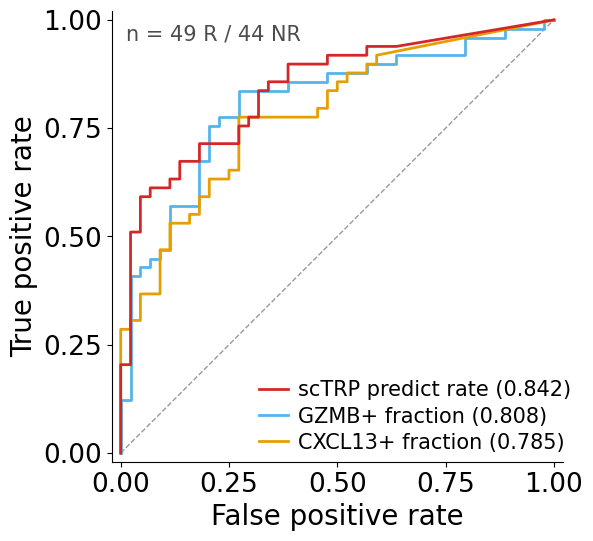

In [72]:
# ── Figure ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot([0, 1], [0, 1], ls='--', lw=1.0, color='0.6', zorder=1)

for r in records:
    ax.plot(r['fpr'], r['tpr'], color=r['color'], lw=2.0,
            solid_joinstyle='round', zorder=3 if r['label'] == REFERENCE else 2,
            label=f"{r['label']} ({r['auc']:.3f})")

ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_aspect('equal')
ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.set_xlabel("False positive rate", fontsize=FS_LABEL)
ax.set_ylabel("True positive rate", fontsize=FS_LABEL)
ax.tick_params(axis='both', labelsize=FS_TICK)

leg = ax.legend(loc='lower right', bbox_to_anchor=(1.02, 0.02),
                fontsize=FS_TICK - 4, frameon=False,
                handlelength=1.4, labelspacing=0.3,
                handletextpad=0.5, borderpad=0.0, borderaxespad=0.0)
leg._legend_box.align = "right"

ax.text(0.03, 0.97, f"n = {n_pos} R / {n_neg} NR", transform=ax.transAxes,
        ha='left', va='top', fontsize=FS_TICK - 4, color='0.3')

sns.despine(ax=ax)
fig.tight_layout()

for ext, kw in [("pdf", {}), ("png", {"dpi": 300})]:
    fig.savefig(f"{input_dir}/ROC_response_prediction_3lines.{ext}", bbox_inches="tight", **kw)

# editable, for Illustrator
with matplotlib.rc_context({"svg.fonttype": "none"}):
    fig.savefig(f"{input_dir}/ROC_response_prediction_editable_3lines.svg", bbox_inches="tight")

# self-contained, for PowerPoint
with matplotlib.rc_context({"svg.fonttype": "path"}):
    fig.savefig(f"{input_dir}/ROC_response_prediction_3lines.svg", bbox_inches="tight")

plt.show()

In [73]:
input_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform')

scTRP predict rate vs GZMB+ fraction         dAUC = +0.033 [-0.059, +0.123]  P = 0.497
scTRP predict rate vs scTRP rank sum norm    dAUC = +0.048 [-0.045, +0.140]  P = 0.318
scTRP predict rate vs CXCL13+ fraction       dAUC = +0.057 [+0.004, +0.112]  P = 0.035
n = 49 responders, 44 non-responders


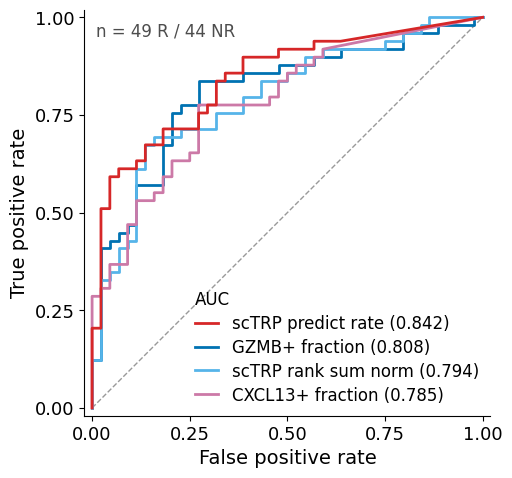

In [101]:
METHODS = [
    # (key into dfs, score column,            display label,        color)
    ('Predict Rate',        'predict_rate',                  'scTRP predict rate',            '#d62728'),
    ('GZMB Expression Rate',                'proportion_GZMB_positive',      'GZMB+ fraction', '#56B4E9'), # light blue
    ('normalized predicts_rank_sum_',            'predicts_rank_sum_normalized',  'scTRP rank sum norm',   '#CC79A7'), # light purple ),
    ('CXCL13 Expression Rate',              'proportion_CXCL13_positive',    'CXCL13+ fraction', '#0072B2'), # dark blue ),
]

REFERENCE = 'scTRP predict rate'   # method all others are compared against

RESPONSE_MAP = {'Response': 1, 'Non_Response': 0}

# ── Assemble, checking sample alignment ───────────────────────────────────────
records, sample_sets = [], {}
for key, score_col, label, color in METHODS:
    d = dfs[key][['sample', 'Response', score_col, 'Response_binary']].dropna().copy()
    d['y'] = d['Response_binary']
    if d['y'].isna().any():
        raise ValueError(f"{label}: unmapped Response values "
                         f"{d.loc[d['y'].isna(), 'Response'].unique()}")
    d = d.set_index('sample').sort_index()
    sample_sets[label] = set(d.index)
    auc = roc_auc_score(d['y'], d[score_col])
    lo, hi = _bootstrap_auc_ci(d['y'], d[score_col])
    fpr, tpr, _ = roc_curve(d['y'], d[score_col])
    records.append(dict(label=label, color=color, auc=auc, ci=(lo, hi),
                        fpr=fpr, tpr=tpr, data=d, score_col=score_col))

common = set.intersection(*sample_sets.values())
if any(s != common for s in sample_sets.values()):
    print(f"WARNING: methods do not share identical samples "
          f"(intersection n={len(common)}); paired comparison uses intersection only.")

records.sort(key=lambda r: r['auc'], reverse=True)   # legend ordered by AUC

# ── Paired comparisons vs reference ───────────────────────────────────────────
ref = next(r for r in records if r['label'] == REFERENCE)
ref_d = ref['data'].loc[sorted(common)]
for r in records:
    if r['label'] == REFERENCE:
        continue
    d = r['data'].loc[sorted(common)]
    p, ci = _bootstrap_auc_diff(ref_d['y'], ref_d[ref['score_col']], d[r['score_col']])
    print(f"{REFERENCE} vs {r['label']:22s} "
          f"dAUC = {ref['auc'] - r['auc']:+.3f} "
          f"[{ci[0]:+.3f}, {ci[1]:+.3f}]  P = {p:.3f}")

n_pos = int(ref['data']['y'].sum()); n_neg = int((ref['data']['y'] == 0).sum())
print(f"n = {n_pos} responders, {n_neg} non-responders")

# ── Figure ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot([0, 1], [0, 1], ls='--', lw=1.0, color='0.6', zorder=1)

for r in records:
    ax.plot(r['fpr'], r['tpr'], color=r['color'], lw=2.0,
            solid_joinstyle='round', zorder=3 if r['label'] == REFERENCE else 2,
            label=f"{r['label']} ({r['auc']:.3f})")

ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_aspect('equal')
ax.set_xticks(np.arange(0, 1.01, 0.25))
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.set_xlabel("False positive rate", fontsize=FS_LABEL)
ax.set_ylabel("True positive rate", fontsize=FS_LABEL)
ax.tick_params(axis='both', labelsize=FS_TICK)

leg = ax.legend(loc='lower right', fontsize=FS_TICK - 1, frameon=False,
                handlelength=1.4, labelspacing=0.35, borderpad=0.2,
                title="AUC", title_fontsize=FS_TICK - 1)
leg._legend_box.align = "left"

ax.text(0.03, 0.97, f"n = {n_pos} R / {n_neg} NR", transform=ax.transAxes,
        ha='left', va='top', fontsize=FS_TICK - 1, color='0.3')

sns.despine(ax=ax)
fig.tight_layout()
#for ext, kw in [("svg", {}), ("pdf", {}), ("png", {"dpi": 300})]:
#    fig.savefig(f"{input_dir}/ROC_response_prediction.{ext}",
#                bbox_inches='tight', **kw)
plt.show()

In [92]:
list(input_dir.glob("*predicts_rank_sum_normalized*.csv"))

[PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Bassez_cohort1_BC_Median_predicts_rank_sum_normalized.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/chiffelle_melanoma_Median_predicts_rank_sum_normalized_box_plot_byresponsedetail.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Cappuyns_aHCC_Median_predicts_rank_sum_normalized.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Chen_CRC_Median_predicts_rank_sum_normalized.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/s

In [93]:
list(input_dir.glob("*Median_Predicts_Sum_box_plot*.csv"))

[PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Bassez_cohort1_BC_Median_Predicts_Sum_box_plot.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Chen_CRC_Median_Predicts_Sum_box_plot.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/chiffelle_melanoma_Median_Predicts_Sum_box_plot_ResponseDetails.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform/Cappuyns_aHCC_Median_Predicts_Sum_box_plot.csv'),
 PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/cla

In [94]:
## Add other two statistics for generating the table:


from pathlib import Path
import pandas as pd


for df_na, str_ in zip(['Median_predicts_sum', 'Median_predicts_rank_sum'],['*Median_Predicts_Sum_box_plot*.csv', '*Median_predicts_rank_sum_box_plot*.csv']):
    all_dfs_ = []
    print(df_na, str_)
    for file_path in input_dir.glob(f"{str_}"):
        # Read the file
        df_ = pd.read_csv(file_path)
        # Extract the prefix from the file stem
        stem = file_path.stem  # e.g., study1_sample1_predicts_sum_proportions_df
        prefix = "_".join(stem.split("_")[:2])  # First two parts
    
    
        all_dfs_.append(df_)
    
    # Concatenate all DataFrames
    Tem_matrix = pd.concat(all_dfs_, ignore_index=True)
    

    # Step 2: Map it onto predictRateTem_matrix based on its 'sample' column
    Tem_matrix['Response'] = Tem_matrix['sample'].map(sample_response_dict)

    print(Tem_matrix.columns)

    # 1. Remove the first column
    Tem_matrix = Tem_matrix.iloc[:, 1:]
    
    col_na_ = df_na.replace('Median_','')
    df = Tem_matrix.groupby(['Response', 'sample'])[f'{col_na_}'].mean().reset_index()
    
    # Rename the column for clarity
    
    #df.dropna(subset=['predict_rate'], inplace=True)
    print(df.shape)
    dfs[df_na] =  df
    


Median_predicts_sum *Median_Predicts_Sum_box_plot*.csv
Index(['Unnamed: 0', 'sample', 'timepoint', 'Response', 'predicts_sum',
       'Treatment', 'Response_detail', 'Tissue', 'Response_detailCode',
       'Timepoint', 'Week'],
      dtype='object')
(93, 3)
Median_predicts_rank_sum *Median_predicts_rank_sum_box_plot*.csv
Index(['Unnamed: 0', 'sample', 'Treatment', 'Response_detail', 'Tissue',
       'predicts_rank_sum', 'Response_detailCode', 'timepoint', 'Response',
       'Week', 'Timepoint'],
      dtype='object')
(93, 3)


In [105]:
for df_n, col_ in zip(list(dfs.keys()), ['predict_rate','proportion_CXCL13_positive', 'predicts_rank_sum_normalized',
                                         'proportion_GZMB_positive', 'predicts_sum', 'predicts_rank_sum']):
    print('====='*10)
    print(df_n)
    print(dfs[df_n].columns)
    print(dfs[df_n].dropna(subset=[col_]).shape)

Predict Rate
Index(['Response', 'study_sample', 'predict_rate', 'ResponseCode',
       'Response_binary', 'sample'],
      dtype='object')
(93, 6)
CXCL13 Expression Rate
Index(['Response', 'study_sample', 'proportion_CXCL13_positive',
       'Response_detailCode', 'Response_binary', 'sample'],
      dtype='object')
(93, 6)
normalized predicts_rank_sum_
Index(['Response', 'sample', 'predicts_rank_sum_normalized',
       'Response_detailCode', 'Response_binary'],
      dtype='object')
(93, 5)
GZMB Expression Rate
Index(['Response', 'study_sample', 'proportion_GZMB_positive',
       'Response_detailCode', 'Response_binary', 'sample'],
      dtype='object')
(93, 6)
Median_predicts_sum
Index(['Response', 'sample', 'predicts_sum'], dtype='object')
(93, 3)
Median_predicts_rank_sum
Index(['Response', 'sample', 'predicts_rank_sum'], dtype='object')
(93, 3)


In [106]:
dfs['Predict Rate'].study_sample.unique()

array(['Bassez_cohort1_BIOKEY_14_Pre', 'Bassez_cohort1_BIOKEY_17_Pre',
       'Bassez_cohort1_BIOKEY_19_Pre', 'Bassez_cohort1_BIOKEY_20_Pre',
       'Bassez_cohort1_BIOKEY_21_Pre', 'Bassez_cohort1_BIOKEY_22_Pre',
       'Bassez_cohort1_BIOKEY_23_Pre', 'Bassez_cohort1_BIOKEY_24_Pre',
       'Bassez_cohort1_BIOKEY_25_Pre', 'Bassez_cohort1_BIOKEY_26_Pre',
       'Bassez_cohort1_BIOKEY_27_Pre', 'Bassez_cohort1_BIOKEY_29_Pre',
       'Bassez_cohort1_BIOKEY_2_Pre', 'Bassez_cohort1_BIOKEY_30_Pre',
       'Bassez_cohort1_BIOKEY_3_Pre', 'Bassez_cohort1_BIOKEY_4_Pre',
       'Bassez_cohort1_BIOKEY_6_Pre', 'Bassez_cohort1_BIOKEY_7_Pre',
       'Bassez_cohort1_BIOKEY_8_Pre', 'Bassez_cohort1_BIOKEY_9_Pre',
       'Bassez_cohort2_BIOKEY_32_Pre', 'Bassez_cohort2_BIOKEY_34_Pre',
       'Bassez_cohort2_BIOKEY_37_Pre', 'Bassez_cohort2_BIOKEY_38_Pre',
       'Bassez_cohort2_BIOKEY_39_Pre', 'Bassez_cohort2_BIOKEY_40_Pre',
       'Bassez_cohort2_BIOKEY_41_Pre', 'Bassez_cohort2_BIOKEY_42_Pre',
       'Cappu

In [107]:
import pandas as pd
from functools import reduce

def get_sample_col(df):
    """Return a Series of sample IDs, deriving from 'study_sample' if 'sample' col is missing."""
    if 'sample' not in df.columns:
        if 'study_sample' not in df.columns:
            raise ValueError("Neither 'sample' nor 'study_sample' column found")
        return df['study_sample'].str.split('_', n=2).str[2]
    return df['sample']

# Step 1: ensure every df has a 'sample' column
for name, df in dfs.items():
    if 'sample' not in df.columns:
        df['sample'] = get_sample_col(df)

# Step 2: assert 'sample' -> 'Response' mapping is consistent across all dfs
response_maps = {}
for name, df in dfs.items():
    m = df.drop_duplicates('sample').set_index('sample')['Response'].to_dict()
    response_maps[name] = m

reference_name = next(iter(response_maps))
reference_map = response_maps[reference_name]

for name, m in response_maps.items():
    common_samples = set(reference_map) & set(m)
    mismatches = {
        s: (reference_map[s], m[s])
        for s in common_samples
        if reference_map[s] != m[s]
    }
    assert not mismatches, (
        f"Response mismatch between '{reference_name}' and '{name}' "
        f"for samples: {mismatches}"
    )

# Step 3: merge all dfs on 'sample', combining the rest of the columns
combined_df = reduce(
    lambda left, right: pd.merge(left, right, on='sample', how='outer', suffixes=('', '_dup')),
    dfs.values()
)

print(combined_df.shape)
combined_df.head()

(93, 24)


,Response,study_sample,predict_rate,ResponseCode,Response_binary,sample,Response_dup,study_sample_dup,proportion_CXCL13_positive,Response_detailCode,...,Response_binary_dup,Response_dup,study_sample_dup,proportion_GZMB_positive,Response_detailCode_dup,Response_binary_dup,Response_dup,predicts_sum,Response_dup,predicts_rank_sum
0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.013761,1,0,BIOKEY_14_Pre,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.006881,1,...,0,Non_Response,Bassez_cohort1_BIOKEY_14_Pre,0.149083,1,0,Non_Response,2.0,Non_Response,35787.5
1,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.000000,1,0,BIOKEY_17_Pre,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.020833,1,...,0,Non_Response,Bassez_cohort1_BIOKEY_17_Pre,0.187500,1,0,Non_Response,2.0,Non_Response,32668.0
2,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.001828,1,0,BIOKEY_19_Pre,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.000000,1,...,0,Non_Response,Bassez_cohort1_BIOKEY_19_Pre,0.115174,1,0,Non_Response,1.0,Non_Response,34095.0
3,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889,1,0,BIOKEY_20_Pre,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889,1,...,0,Non_Response,Bassez_cohort1_BIOKEY_20_Pre,0.088889,1,0,Non_Response,5.0,Non_Response,44779.0
4,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.000000,1,0,BIOKEY_21_Pre,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.000000,1,...,0,Non_Response,Bassez_cohort1_BIOKEY_21_Pre,0.153846,1,0,Non_Response,1.0,Non_Response,27165.0


In [79]:
response_maps

{'Predict Rate': {'BIOKEY_14_Pre': 'Non_Response',
  'BIOKEY_17_Pre': 'Non_Response',
  'BIOKEY_19_Pre': 'Non_Response',
  'BIOKEY_20_Pre': 'Non_Response',
  'BIOKEY_21_Pre': 'Non_Response',
  'BIOKEY_22_Pre': 'Non_Response',
  'BIOKEY_23_Pre': 'Non_Response',
  'BIOKEY_24_Pre': 'Non_Response',
  'BIOKEY_25_Pre': 'Non_Response',
  'BIOKEY_26_Pre': 'Non_Response',
  'BIOKEY_27_Pre': 'Non_Response',
  'BIOKEY_29_Pre': 'Non_Response',
  'BIOKEY_2_Pre': 'Non_Response',
  'BIOKEY_30_Pre': 'Non_Response',
  'BIOKEY_3_Pre': 'Non_Response',
  'BIOKEY_4_Pre': 'Non_Response',
  'BIOKEY_6_Pre': 'Non_Response',
  'BIOKEY_7_Pre': 'Non_Response',
  'BIOKEY_8_Pre': 'Non_Response',
  'BIOKEY_9_Pre': 'Non_Response',
  'BIOKEY_32_Pre': 'Non_Response',
  'BIOKEY_34_Pre': 'Non_Response',
  'BIOKEY_37_Pre': 'Non_Response',
  'BIOKEY_38_Pre': 'Non_Response',
  'BIOKEY_39_Pre': 'Non_Response',
  'BIOKEY_40_Pre': 'Non_Response',
  'BIOKEY_41_Pre': 'Non_Response',
  'BIOKEY_42_Pre': 'Non_Response',
  'Cappuyns

In [108]:
combined_df.columns

Index(['Response', 'study_sample', 'predict_rate', 'ResponseCode',
       'Response_binary', 'sample', 'Response_dup', 'study_sample_dup',
       'proportion_CXCL13_positive', 'Response_detailCode',
       'Response_binary_dup', 'Response_dup', 'predicts_rank_sum_normalized',
       'Response_detailCode_dup', 'Response_binary_dup', 'Response_dup',
       'study_sample_dup', 'proportion_GZMB_positive',
       'Response_detailCode_dup', 'Response_binary_dup', 'Response_dup',
       'predicts_sum', 'Response_dup', 'predicts_rank_sum'],
      dtype='object')

In [109]:
combined_df.index

Int64Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
            17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
            34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
            51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
            68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
            85, 86, 87, 88, 89, 90, 91, 92],
           dtype='int64')

In [110]:
input_dir

PosixPath('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_20260630_combine_6_models_Uniform')

In [111]:
col_tokeep = ['sample','Response','predict_rate', 'proportion_CXCL13_positive','predicts_rank_sum_normalized','proportion_GZMB_positive','predicts_sum', 'predicts_rank_sum']

combined_df_ = combined_df[col_tokeep]
print(combined_df_.shape)

combined_df_.to_csv(f"{input_dir}/combined_6statistics_bySample_df.csv", index=False)

(93, 8)


### Test genes revealed by scTRP-derived GRN
### Supplementary Table 3.

In [13]:
from pathlib import Path
import pandas as pd

from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score


input_dir = Path('/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/case_study/case_study89_ICB_0913_combine_6_models/')


In [14]:
import pandas as pd
import glob
import os

dir_path_ = "/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814/rankMin_study_clonotype/"

gene_list_ = []

# find all csv files (change pattern if needed)
files = glob.glob(os.path.join(dir_path_, "GRN_gene_embedding_Chiffelle_genes_celltype*.csv"))

for f in files:
    df = pd.read_csv(f)
    
    # assume single column
    genes = df.iloc[:,0].dropna().astype(str).tolist()
    
    gene_list_.extend(genes)

# remove duplicates if desired
gene_list_ = list(set(gene_list_))

print(len(gene_list_), "genes loaded")

list_gene_name_ = gene_list_
#list_gene_name  = [g for g in gene_list if g in list(study_log_ad.var_names)]

47 genes loaded


In [38]:
list_gene_name_

['CCR7',
 'FGFBP2',
 'TIGIT',
 'LGALS1',
 'KLRC1',
 'SAT1',
 'GADD45B',
 'ANXA1',
 'TNFRSF18',
 'TUBA1B',
 'KLRD1',
 'HMOX1',
 'HSPA1B',
 'GZMH',
 'FOS',
 'CD83',
 'MYC',
 'GZMB',
 'CCL4L2',
 'HSPA1A',
 'TNF',
 'DNAJB1',
 'TRDV1',
 'GNLY',
 'HLA-DRA',
 'TIMP1',
 'ZNF683',
 'TRGV5',
 'GZMA',
 'LEF1',
 'DUSP1',
 'DUSP2',
 'KLRG1',
 'FTL',
 'FASLG',
 'TRDC',
 'CD69',
 'CCL4',
 'RGS1',
 'TUBB',
 'STMN1',
 'HSPB1',
 'CCL3',
 'IFNG',
 'MAL',
 'XCL2',
 'IRF4']

In [15]:
files

['/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814/rankMin_study_clonotype/GRN_gene_embedding_Chiffelle_genes_celltype_1.csv',
 '/cluster/pixstor/xudong-lab/suli/Alg_development/scRNA_TCRBCR_surfaceProtein/results/classifier/model_explainability/Model_expl_20260814/rankMin_study_clonotype/GRN_gene_embedding_Chiffelle_genes_celltype_0.csv']

In [17]:
list_gene_name_.append('CXCL13')

In [19]:
len(list_gene_name_)

48

In [20]:


# inputs you already have:
# input_dir = Path("...") 
# score_matrix = ...  # used for the study_sample assertion (optional)
# list_gene_name = ["CXCL13", "FOXP3", ...]  # your list

results = []

for gene_name in list_gene_name_:
    # --- load & stack this gene's files ---
    all_dfs = []
    for file_path in input_dir.glob(f"*proportion_{gene_name}_positive.csv"):
        df = pd.read_csv(file_path)
        stem = file_path.stem
        # if you need 'study_sample' and it's not in the file, derive it here (uncomment if needed)
        # prefix = "_".join(stem.split("_")[:2])
        # if "study_sample" not in df.columns:
        #     if "sample" in df.columns:
        #         df["study_sample"] = prefix + "_" + df["sample"].astype(str)
        #     else:
        #         raise ValueError(f"'sample' column missing in {file_path.name} for building study_sample.")
        all_dfs.append(df)

    if not all_dfs:
        # no files for this gene; skip
        continue

    targetGene_matrix = pd.concat(all_dfs, ignore_index=True)

    # optional assertion if 'study_sample' is present in both frames
    if "study_sample" in targetGene_matrix.columns and "study_sample" in score_matrix.columns:
        assert len(set(targetGene_matrix['study_sample']) - set(score_matrix['study_sample'])) == 0, \
            f"study_sample mismatch for {gene_name}"

    # drop the first column if you truly need to 
    targetGene_matrix = targetGene_matrix.iloc[:, 1:]

    # compute per (Response, study_sample) mean
    col_name = f'proportion_{gene_name}_positive'
    if col_name not in targetGene_matrix.columns:
        # column not present; skip this gene
        continue

    predict_rate = (
        targetGene_matrix
        .groupby(['Response', 'study_sample'], as_index=False)[col_name]
        .mean()
        .dropna(subset=[col_name])
    )

    # split groups
    resp_vals = predict_rate.loc[predict_rate['Response'] == 'Response', col_name]
    nonresp_vals = predict_rate.loc[predict_rate['Response'] == 'Non_Response', col_name]

    # need both groups non-empty for tests
    if resp_vals.empty or nonresp_vals.empty:
        continue

    # Mann–Whitney U (two-sided)
    try:
        u_stat, p_u = mannwhitneyu(resp_vals, nonresp_vals, alternative='two-sided')
    except ValueError:
        # identical distributions or invalid input
        continue

    # Only keep if p < 0.05
    if p_u < 0.05:
        # Spearman (encode Response to ordinal)
        # Non_Response -> 1, Response -> 2 (as in your code)
        category_map = {'Non_Response': 1, 'Response': 2}
        pr = predict_rate.copy()
        pr['Response_detailCode'] = pr['Response'].map(category_map)

        rho, p_s = spearmanr(pr['Response_detailCode'], pr[col_name])

        # ROC AUC
        df_auc = predict_rate.copy()
        df_auc['Response_binary'] = df_auc['Response'].map({'Response': 1, 'Non_Response': 0})

        # make sure there are both classes after dropna
        valid = df_auc['Response_binary'].notna() & df_auc[col_name].notna()
        y_true = df_auc.loc[valid, 'Response_binary']
        y_score = df_auc.loc[valid, col_name]

        if y_true.nunique() == 2:
            auc = roc_auc_score(y_true, y_score)
        else:
            auc = float('nan')

        results.append({
            'gene_name': gene_name,
            'mannwhitneyu_p': p_u,
            'spearman_rho': rho,
            'spearman_p': p_s,
            'auc': auc,
            'n_Response': int(resp_vals.shape[0]),
            'n_Non_Response': int(nonresp_vals.shape[0]),
        })

# Collect into a DataFrame, sort by p-value (ascending)
sig_results_df = pd.DataFrame(results).sort_values(['mannwhitneyu_p', 'auc'], ascending=[True, False]).reset_index(drop=True)

print(sig_results_df)

# (optional) save to CSV
# sig_results_df.to_csv("significant_genes_stats.csv", index=False)


   gene_name  mannwhitneyu_p  spearman_rho    spearman_p       auc  \
0       GZMB    3.165614e-07      0.533501  3.667649e-08  0.808442   
1     CXCL13    2.011034e-06      0.495867  4.325006e-07  0.784787   
2       IRF4    1.089778e-05      0.458981  3.705175e-06  0.765306   
3       RGS1    3.971760e-05      0.428806  1.799570e-05  0.747913   
4      TIGIT    7.055400e-05      0.414762  3.572631e-05  0.739796   
5      HMOX1    1.075010e-04      0.404193  5.868635e-05  0.731911   
6   TNFRSF18    7.512422e-04      0.351765  5.449677e-04  0.703154   
7      TIMP1    1.297703e-03     -0.335743  1.001696e-03  0.305891   
8       IFNG    2.084021e-03      0.321304  1.687491e-03  0.685761   
9    HLA-DRA    4.411683e-03      0.297234  3.811609e-03  0.671846   
10    HSPA1A    5.280459e-03      0.291217  4.624778e-03  0.668367   
11      GZMH    1.519107e-02      0.253516  1.420837e-02  0.646568   
12      XCL2    1.618785e-02     -0.251103  1.518912e-02  0.354824   
13      CCL3    1.70

In [21]:
sig_results_df.to_csv(f"{dir_path_}/GRN_gene_embedding_significant_genes_stats.csv", index=False)